In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [54]:
df = pd.read_csv(r"C:\netflex project nti\netflix_titles.csv")
CLEAN_PATH =r"C:\netflex project nti\clean.csv"

In [55]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [56]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [57]:
df.sample()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
4894,s4895,Movie,Pocoyo Carnival,NaN,"Stephen Fry, Alex Marty",NaN,"May 1, 2018",2015,TV-Y,22 min,Movies,"To celebrate the carnival, everyone learns to ..."


In [58]:
df.describe()

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [59]:
df.duplicated().sum()

np.int64(0)

In [60]:
df["show_id"].duplicated().sum()

np.int64(0)

In [61]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [62]:
df.isnull().mean().mul(100).round(2)

show_id          0.00
type             0.00
title            0.00
director        29.91
cast             9.37
country          9.44
date_added       0.11
release_year     0.00
rating           0.05
duration         0.03
listed_in        0.00
description      0.00
dtype: float64

In [63]:
df["type"].value_counts()

type
Movie      6131
TV Show    2676
Name: count, dtype: int64

In [64]:
df[["director", "cast", "country"]].isnull().groupby(df["type"]).mean().mul(100).round(1)

,director,cast,country
type,,,
Movie,3.1,7.7,7.2
TV Show,91.4,13.1,14.6


In [65]:
df[df["rating"].str.contains("min", na=False)][["title", "type", "rating", "duration"]]

,title,type,rating,duration
5541,Louis C.K. 2017,Movie,74 min,NaN
5794,Louis C.K.: Hilarious,Movie,84 min,NaN
5813,Louis C.K.: Live at the Comedy Store,Movie,66 min,NaN


In [66]:
text_cols = ["show_id", "type", "title", "director", "cast", "country", "date_added", "rating", "duration", "listed_in", "description"]
for c in text_cols:
    df[c] = df[c].str.strip().replace("", np.nan)

In [67]:
mask = df["rating"].str.contains("min", na=False)
df.loc[mask, "duration"] = df.loc[mask, "rating"]
df.loc[mask, "rating"] = np.nan
print("Rows fixed:", mask.sum())

Rows fixed: 3


In [68]:
df["date_added"] = pd.to_datetime(df["date_added"], format="%B %d, %Y", errors="coerce")

In [69]:
df["year_added"] = df["date_added"].dt.year.astype("Int64")
df["month_added"] = df["date_added"].dt.month.astype("Int64")
df["month_name"] = df["date_added"].dt.month_name()

In [70]:
df["years_to_netflix"] = (df["year_added"] - df["release_year"]).astype("Int64")

In [71]:
dur = df["duration"].str.extract(r"(\d+)\s*([A-Za-z]+)")
df["duration_value"] = pd.to_numeric(dur[0]).astype("Int64")
df["duration_unit"] = np.where(dur[1].str.lower().str.startswith("min", na=False), "min", "seasons")

In [72]:
age_map = {
    "TV-Y": "Kids", "TV-Y7": "Kids", "TV-Y7-FV": "Kids", "TV-G": "Kids", "G": "Kids",
    "TV-PG": "Older Kids", "PG": "Older Kids",
    "TV-14": "Teens", "PG-13": "Teens",
    "TV-MA": "Adults", "R": "Adults", "NC-17": "Adults",
}
df["age_group"] = df["rating"].map(age_map).fillna("Unrated")

In [73]:
print("total null values after cleaning:")
print(df.isnull().sum())

total null values after cleaning:
show_id                0
type                   0
title                  0
director            2634
cast                 825
country              831
date_added            10
release_year           0
rating                 7
duration               0
listed_in              0
description            0
year_added            10
month_added           10
month_name            10
years_to_netflix      10
duration_value         0
duration_unit          0
age_group              0
dtype: int64


In [74]:
print("Duplicated column names:", df.columns.duplicated().sum())
assert df.shape == (8807, 19), f"Expected (8807, 19), got {df.shape}"
assert not df.columns.duplicated().any(), "Duplicate column names found"
assert df["duration"].notnull().all(), "duration still has nulls"
assert df["type"].value_counts()["Movie"] == 6131
assert df["type"].value_counts()["TV Show"] == 2676

Duplicated column names: 0


In [75]:
print(df.dtypes)

show_id                        str
type                           str
title                          str
director                       str
cast                           str
country                        str
date_added          datetime64[us]
release_year                 int64
rating                         str
duration                       str
listed_in                      str
description                    str
year_added                   Int64
month_added                  Int64
month_name                     str
years_to_netflix             Int64
duration_value               Int64
duration_unit                  str
age_group                      str
dtype: object


In [76]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added,month_added,month_name,years_to_netflix,duration_value,duration_unit,age_group
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021,9,September,1,90,min,Teens
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021,9,September,0,2,seasons,Adults
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021,9,September,0,1,seasons,Adults
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021,9,September,0,1,seasons,Adults
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021,9,September,0,2,seasons,Adults


In [77]:
def explode_col(frame, col, new_name):
    out = frame[["show_id", col]].dropna().copy()
    out[new_name] = out[col].str.split(",")
    out = out.explode(new_name)
    out[new_name] = out[new_name].str.strip()
    out = out[out[new_name] != ""][["show_id", new_name]].drop_duplicates()
    return out.reset_index(drop=True)

In [78]:
genres = explode_col(df, "listed_in", "genre")
countries = explode_col(df, "country", "country")
directors = explode_col(df, "director", "director")
actors = explode_col(df, "cast", "actor")

In [79]:
print("genres   :", genres.shape, genres["genre"].nunique(), "distinct")
print("countries:", countries.shape, countries["country"].nunique(), "distinct")
print("directors:", directors.shape, directors["director"].nunique(), "distinct")
print("actors   :", actors.shape, actors["actor"].nunique(), "distinct")

genres   : (19323, 2) 42 distinct
countries: (10012, 2) 122 distinct
directors: (6977, 2) 4993 distinct
actors   : (64124, 2) 36439 distinct


In [80]:
genres_m = genres.merge(df[["show_id", "type"]], on="show_id")

<Axes: title={'center': 'Movies vs TV Shows'}>

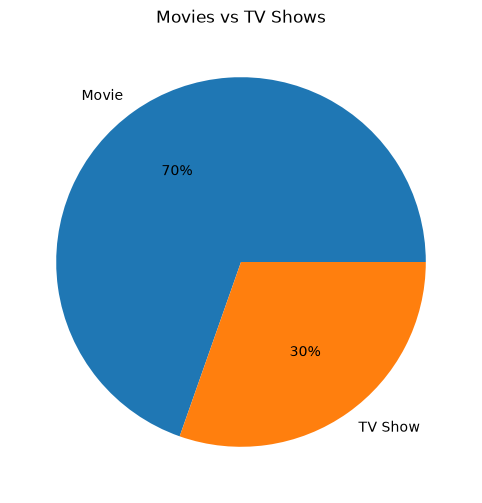

In [81]:
df["type"].value_counts().plot(kind="pie", title="Movies vs TV Shows", autopct="%1.f%%", figsize=(6, 6))

<Axes: title={'center': 'Titles added per year'}, xlabel='year_added', ylabel='count'>

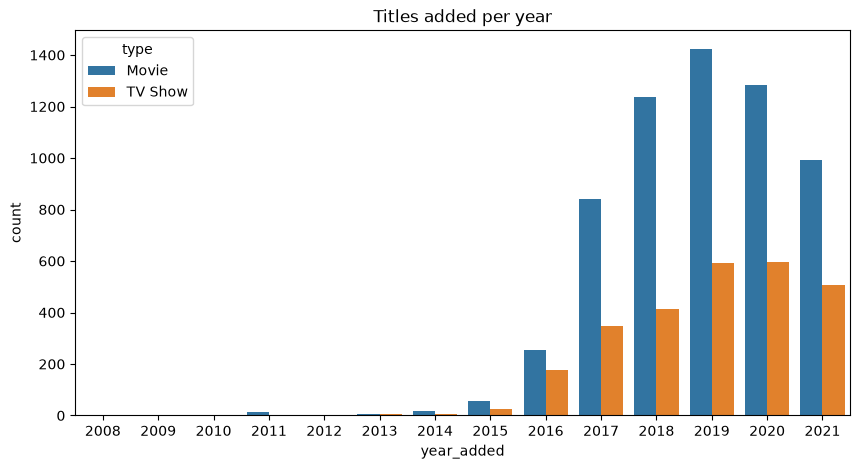

In [82]:
yearly = df.dropna(subset=["year_added"]).copy()
yearly["year_added"] = yearly["year_added"].astype(int)
plt.figure(figsize=(10, 5))
plt.title("Titles added per year")
sns.countplot(data=yearly, x="year_added", hue="type")

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11],
 [Text(0, 0, 'January'),
  Text(1, 0, 'February'),
  Text(2, 0, 'March'),
  Text(3, 0, 'April'),
  Text(4, 0, 'May'),
  Text(5, 0, 'June'),
  Text(6, 0, 'July'),
  Text(7, 0, 'August'),
  Text(8, 0, 'September'),
  Text(9, 0, 'October'),
  Text(10, 0, 'November'),
  Text(11, 0, 'December')])

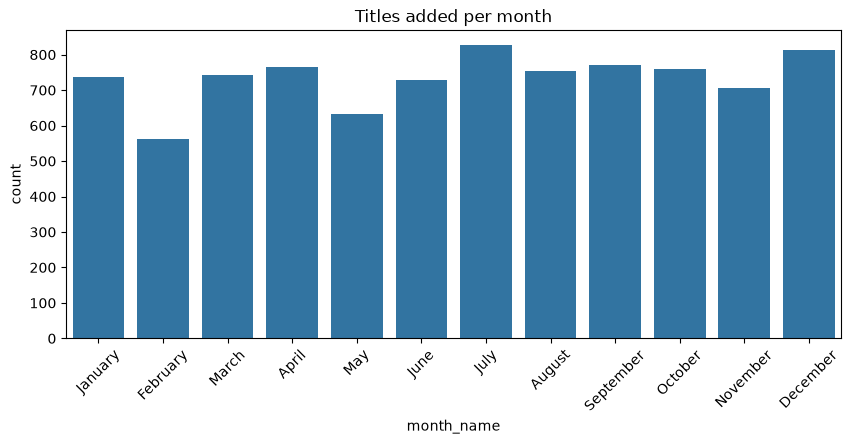

In [83]:
months = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
plt.figure(figsize=(10, 4))
plt.title("Titles added per month")
sns.countplot(data=df, x="month_name", order=months)
plt.xticks(rotation=45)

<Axes: title={'center': 'Release year (1990+)'}, xlabel='release_year', ylabel='Count'>

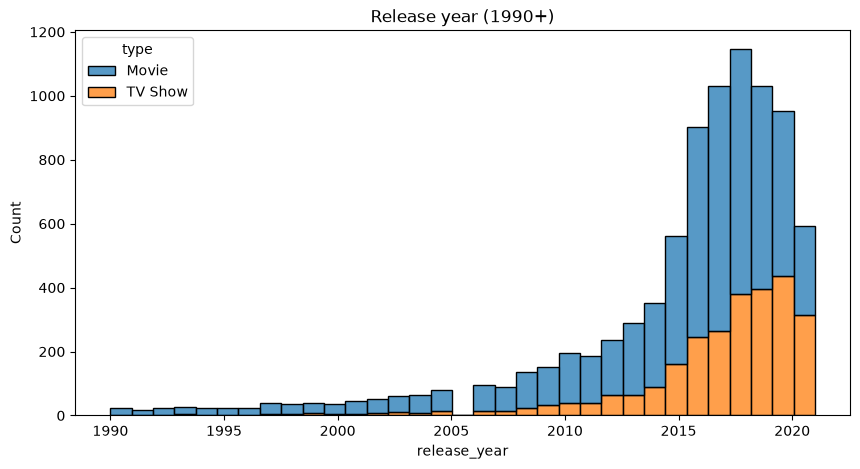

In [84]:
plt.figure(figsize=(10, 5))
plt.title("Release year (1990+)")
sns.histplot(data=df[df["release_year"] >= 1990], x="release_year", hue="type", bins=33, multiple="stack")

<Axes: title={'center': 'Years between release and Netflix by type'}, xlabel='type', ylabel='years_to_netflix'>

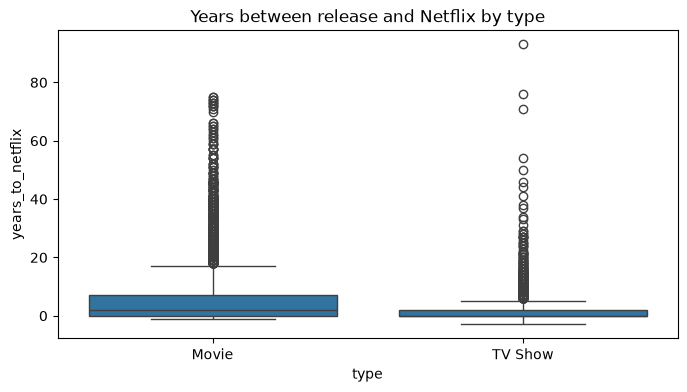

In [85]:
plt.figure(figsize=(8, 4))
plt.title("Years between release and Netflix by type")
sns.boxplot(data=df.assign(years_to_netflix=df["years_to_netflix"].astype(float)), x="type", y="years_to_netflix")

<Axes: title={'center': 'Top 10 genres'}, ylabel='genre'>

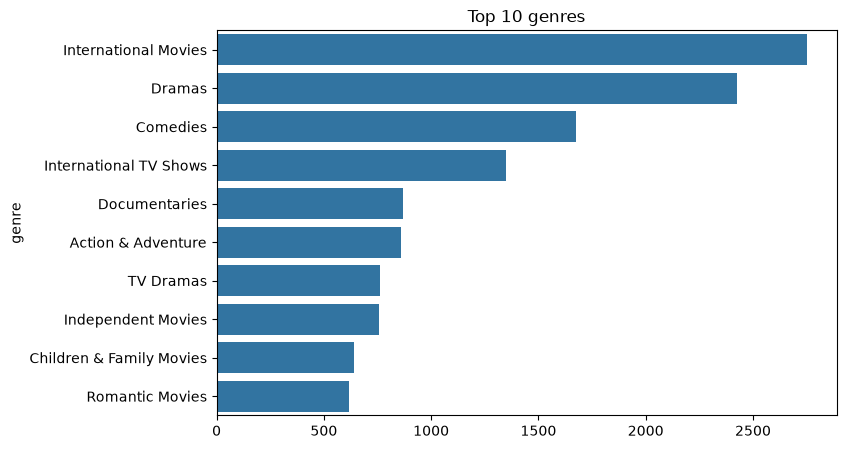

In [86]:
top_genres = genres["genre"].value_counts().head(10)
plt.figure(figsize=(8, 5))
plt.title("Top 10 genres")
sns.barplot(x=top_genres.values, y=top_genres.index)

<Axes: title={'center': 'Top 5 genres per type'}, xlabel='titles', ylabel='genre'>

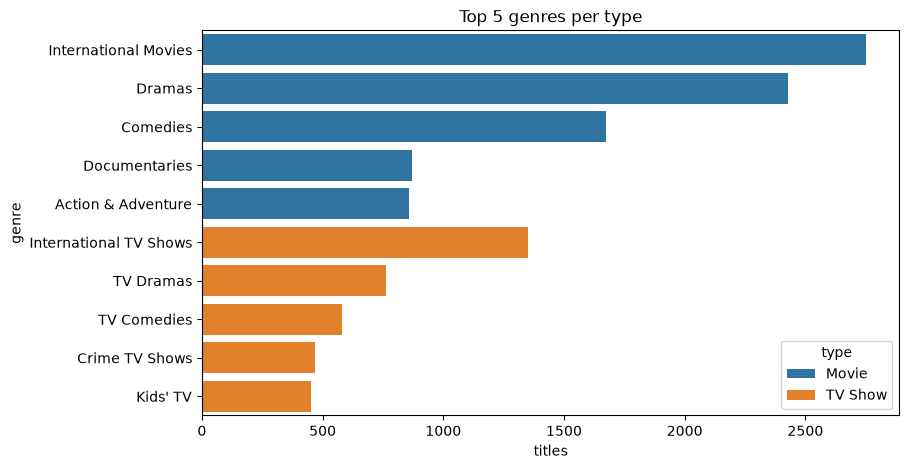

In [87]:
top_by_type = genres_m.groupby("type")["genre"].value_counts().groupby(level=0).head(5).reset_index(name="titles")
plt.figure(figsize=(9, 5))
plt.title("Top 5 genres per type")
sns.barplot(data=top_by_type, x="titles", y="genre", hue="type", dodge=False)

<Axes: title={'center': 'Top 10 countries'}, ylabel='country'>

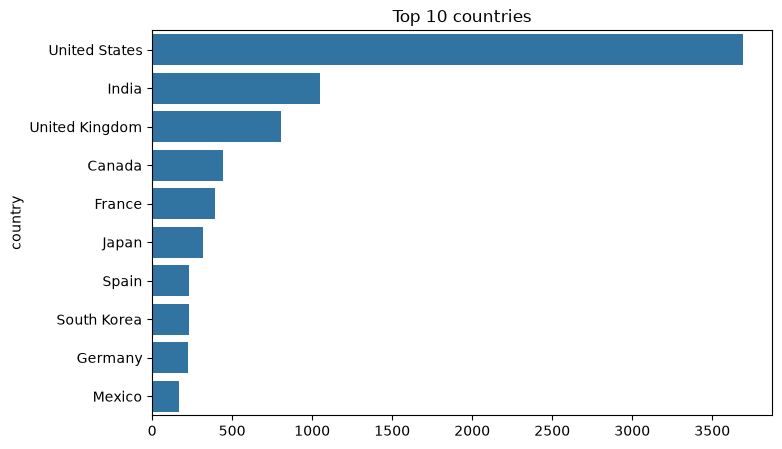

In [88]:
top_countries = countries["country"].value_counts().head(10)
plt.figure(figsize=(8, 5))
plt.title("Top 10 countries")
sns.barplot(x=top_countries.values, y=top_countries.index)

<Axes: title={'center': 'Share of titles by year added (%)'}, xlabel='year_added'>

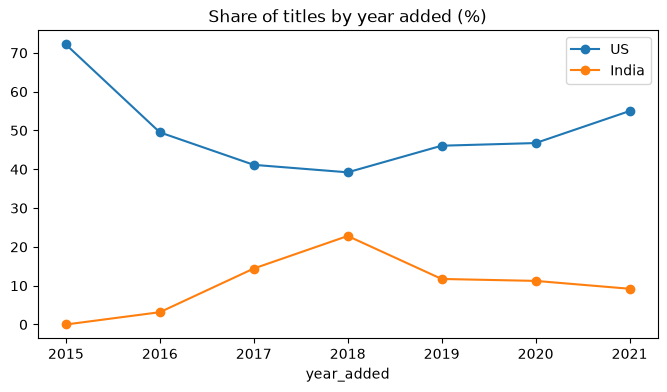

In [89]:
c = df[df["country"].notna() & (df["year_added"] >= 2015).fillna(False)].copy()
c["US"] = c["country"].str.contains("United States")
c["India"] = c["country"].str.contains("India")
share = c.groupby("year_added")[["US", "India"]].mean().mul(100)
share.plot(marker="o", title="Share of titles by year added (%)", figsize=(8, 4))

<Axes: title={'center': 'Rating distribution'}, xlabel='count', ylabel='rating'>

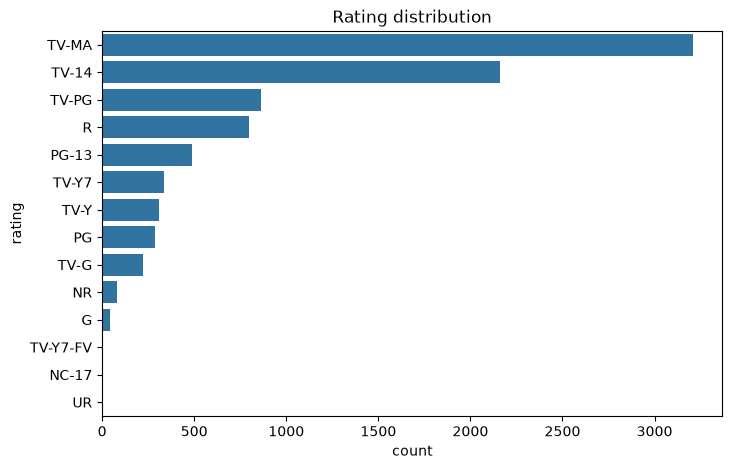

In [90]:
plt.figure(figsize=(8, 5))
plt.title("Rating distribution")
sns.countplot(data=df, y="rating", order=df["rating"].value_counts().index)

<Axes: title={'center': 'Age group by type'}, xlabel='age_group', ylabel='count'>

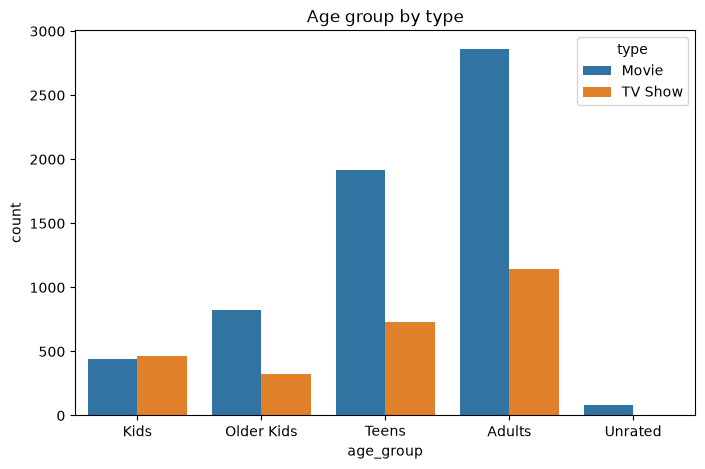

In [91]:
plt.figure(figsize=(8, 5))
plt.title("Age group by type")
sns.countplot(data=df, x="age_group", hue="type", order=["Kids", "Older Kids", "Teens", "Adults", "Unrated"])

<Axes: title={'center': 'Movie duration (minutes)'}, xlabel='duration_value', ylabel='Count'>

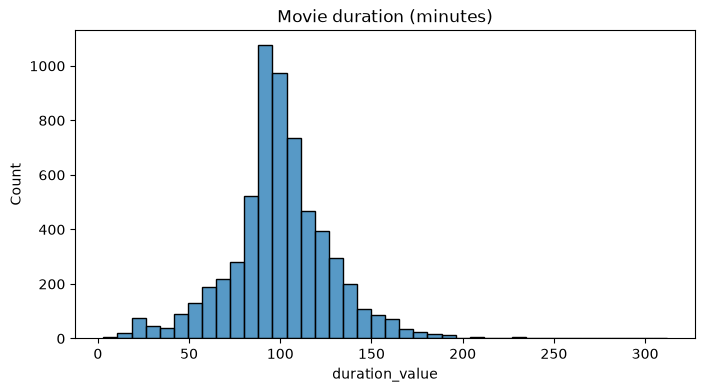

In [92]:
movies = df[(df["type"] == "Movie") & df["duration_value"].notna()]
plt.figure(figsize=(8, 4))
plt.title("Movie duration (minutes)")
sns.histplot(movies["duration_value"].astype(int), bins=40)

<Axes: title={'center': 'TV Shows by number of seasons (9 = 9+)'}, xlabel='duration_value', ylabel='count'>

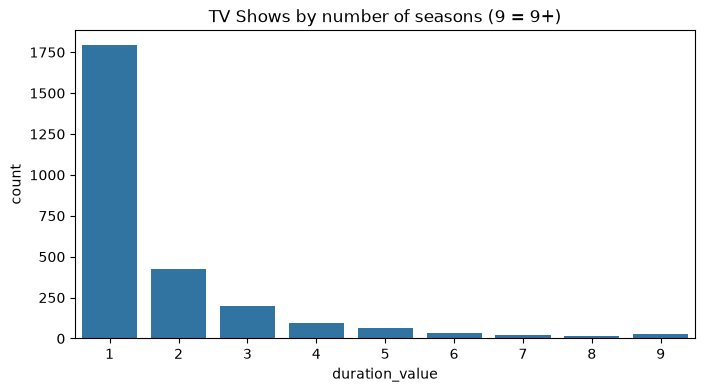

In [93]:
tv = df[(df["type"] == "TV Show") & df["duration_value"].notna()]
plt.figure(figsize=(8, 4))
plt.title("TV Shows by number of seasons (9 = 9+)")
sns.countplot(x=tv["duration_value"].astype(int).clip(upper=9))

<Axes: title={'center': 'Top 10 directors'}, ylabel='director'>

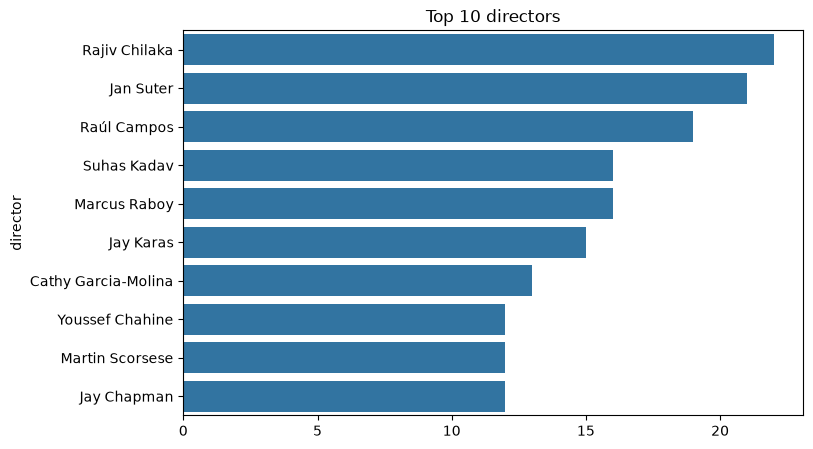

In [94]:
top_directors = directors["director"].value_counts().head(10)
plt.figure(figsize=(8, 5))
plt.title("Top 10 directors")
sns.barplot(x=top_directors.values, y=top_directors.index)

<Axes: title={'center': 'Top 10 actors'}, ylabel='actor'>

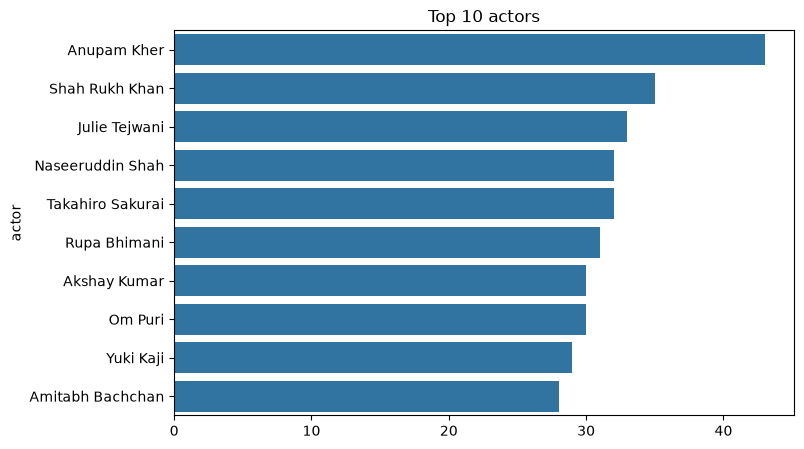

In [95]:
top_actors = actors["actor"].value_counts().head(10)
plt.figure(figsize=(8, 5))
plt.title("Top 10 actors")
sns.barplot(x=top_actors.values, y=top_actors.index)

In [96]:
top_c = countries["country"].value_counts().head(8).index
top_g = genres["genre"].value_counts().head(10).index
cg = countries[countries["country"].isin(top_c)].merge(genres[genres["genre"].isin(top_g)], on="show_id")
heat = pd.crosstab(cg["country"], cg["genre"]).loc[top_c, top_g]
heat_pct = heat.div(countries["country"].value_counts().reindex(heat.index), axis=0) * 100

(array([0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]),
 [Text(0.5, 0, 'International Movies'),
  Text(1.5, 0, 'Dramas'),
  Text(2.5, 0, 'Comedies'),
  Text(3.5, 0, 'International TV Shows'),
  Text(4.5, 0, 'Documentaries'),
  Text(5.5, 0, 'Action & Adventure'),
  Text(6.5, 0, 'TV Dramas'),
  Text(7.5, 0, 'Independent Movies'),
  Text(8.5, 0, 'Children & Family Movies'),
  Text(9.5, 0, 'Romantic Movies')])

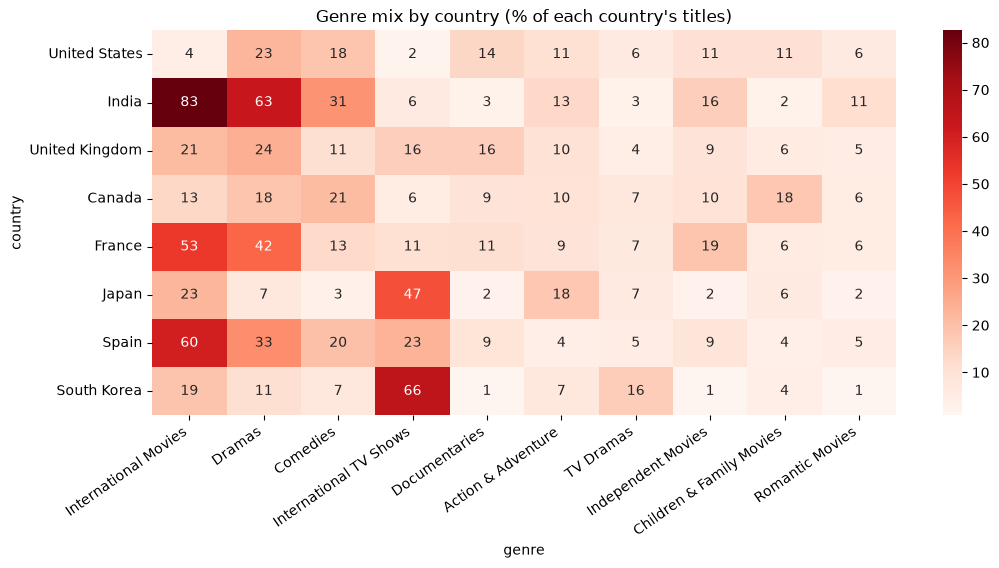

In [97]:
plt.figure(figsize=(12, 5))
plt.title("Genre mix by country (% of each country's titles)")
sns.heatmap(heat_pct, annot=True, fmt=".0f", cmap="Reds")
plt.xticks(rotation=35, ha="right")

<Axes: title={'center': 'Correlation (movies)'}>

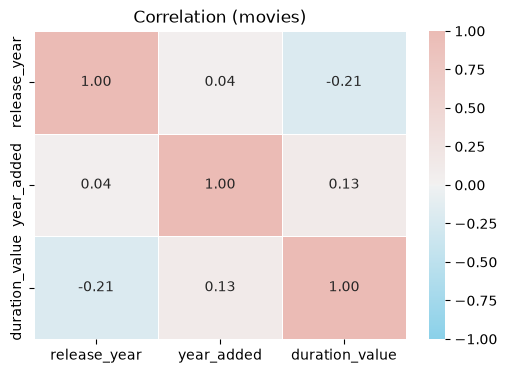

In [98]:
plt.figure(figsize=(6, 4))
plt.title("Correlation (movies)")
sns.heatmap(movies[["release_year", "year_added", "duration_value"]].astype(float).corr(),
            annot=True, fmt=".2f", linewidths=0.5, center=0, vmin=-1, vmax=1,
            cmap=sns.diverging_palette(220, 20, s=60, l=80, as_cmap=True))

In [99]:
df.to_csv(CLEAN_PATH, index=False)
print("Saved:", df.shape)

Saved: (8807, 19)


In [100]:
print(pd.read_csv(CLEAN_PATH).shape)

(8807, 19)
